# 05 — Ablação de histórico, calendário e cardápio

Este notebook estima a contribuição de cada grupo de atributos para a previsão do consumo. Mantém as mesmas origens semanais, horizonte de sete dias e alvos do Notebook 03. O Notebook 04 já comparou todos os 20 candidatos e nove ensembles com a base completa. Para isolar a contribuição das variáveis sem multiplicar por quatro toda a competição, esta ablação reavalia oito representantes: BayesianRidge e Ridge (lineares), ExtraTrees (árvore), LightGBM, CatBoost e XGBoost (boosting), MLP (rede neural) e Prophet (série temporal com regressores). Os ensembles são recalculados dentro de cada configuração, sempre com previsões OOF anteriores.

## Condições

1. **Histórico:** somente atributos construídos com consumos anteriores à origem.
2. **Histórico + calendário:** acrescenta dia da semana, sazonalidade e informação acadêmica conhecida.
3. **Histórico + cardápio:** acrescenta pratos, grupos de proteína/preparo, presença do cardápio e popularidade histórica suavizada.
4. **Base completa do Notebook 04:** referência observada no experimento anterior, com todos os preditores disponíveis e o comitê formado pelos 20 candidatos.

O SARIMAX já foi avaliado no Notebook 04 como série sem covariáveis; repetir sua previsão em cada condição não mediria contribuição de atributos. Por isso, ele não é duplicado aqui. A mediana sazonal do Notebook 03 também serve de referência. A ablação é uma análise retrospectiva e exploratória; o conjunto de variáveis deve ser escolhido dentro de treino temporal se for convertido em regra de produção.

Todos os pré-processadores permanecem dentro dos folds. A diferença é somente a lista de preditores elegível: imputadores, One-Hot Encoding, escala, remoção de constantes e estimadores são ajustados novamente apenas com os dados disponíveis naquela origem.

As comparações de ensembles entre a condição completa (20 candidatos) e reduzidas (oito) também alteram o comitê. Para isolar atributos, interprete os estimadores individuais nas mesmas datas. O reuso de resultados exige opção explícita e manifesto com hashes de código, dados e previsões.


In [1]:
from pathlib import Path
from datetime import datetime
import shutil
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
SCRIPTS = ROOT / "scripts"
if str(SCRIPTS) not in sys.path: sys.path.insert(0, str(SCRIPTS))
from feature_engineering_temporal import read_gold, read_calendar, get_predictor_columns
from competir_modelos_temporalmente import run_competition, aggregate_metrics

FEATURES_PATH = FEATURES_DIR / "features_supervisionadas_horizonte_7d.csv"
FOLDS_PATH = LINE_RESULTS / "03_baselines_walk_forward/folds_walk_forward.csv"
BASELINE_PATH = LINE_RESULTS / "03_baselines_walk_forward/previsoes_baselines_pareadas.csv"
FULL_PATH = LINE_RESULTS / "04_competicao_modelos_ensembles/previsoes_modelos_ensembles_baselines.csv"
OUT = LINE_RESULTS / "05_ablation_grupos_features"
if OUT.exists() and any(OUT.iterdir()):
    backup = ROOT / "backup" / f"resultados_05_{datetime.now():%Y%m%d_%H%M%S}"
    backup.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT, backup)
    print(f"Resultados anteriores preservados em: {backup}")
OUT.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

features = pd.read_csv(FEATURES_PATH, encoding="utf-8-sig", low_memory=False)
features["data_alvo"] = pd.to_datetime(features["data_alvo"], errors="raise").dt.normalize()
features["origem_previsao"] = pd.to_datetime(features["origem_previsao"], errors="coerce").dt.normalize()
gold, calendar = read_gold(), read_calendar()
folds = pd.read_csv(FOLDS_PATH, encoding="utf-8-sig")
folds["origem"] = pd.to_datetime(folds["origem"], errors="raise").dt.normalize()
baseline_raw = pd.read_csv(BASELINE_PATH, encoding="utf-8-sig")
baseline_raw["data"] = pd.to_datetime(baseline_raw["data"], errors="raise").dt.normalize()
full_raw = pd.read_csv(FULL_PATH, encoding="utf-8-sig", low_memory=False)
full_raw["data"] = pd.to_datetime(full_raw["data"], errors="raise", format="mixed").dt.normalize()

predictors = get_predictor_columns(features)
menu_exact = {"prato_principal", "tipo_proteina_principal", "tipo_preparo_principal", "opcao_vegetariana", "guarnicao", "sobremesa", "cardapio_presente", "cardapio_ausente", "dia_semana_x_proteina", "dia_semana_x_preparo"}
calendar_exact = {"ano", "mes", "dia_mes", "dia_semana_num", "semana_ano", "is_inicio_mes", "is_fim_mes", "dia_semana_x_status_letivo"}
history_prefixes = ("consumo_", "n_observacoes_janela_", "n_observacoes_historicas_", "dias_desde_ultimo_consumo_", "tendencia_media_")
menu_prefixes = ("popularidade_historica_", "n_historico_")
calendar_prefixes = ("dia_semana_sin", "dia_semana_cos", "mes_sin", "mes_cos", "dia_ano_sin", "dia_ano_cos", "is_", "dias_desde_feriado", "dias_ate_proximo_feriado", "dias_ate_inicio_ferias", "dias_desde_fim_ferias", "is_semana_anterior_ferias", "evento_")

history_cols, calendar_cols, menu_cols = [], [], []
for col in predictors:
    if col in menu_exact or col.startswith(menu_prefixes): menu_cols.append(col)
    elif col in calendar_exact or col.startswith(calendar_prefixes) or col in {"status_legal", "evento_tipo"}: calendar_cols.append(col)
    elif col.startswith(history_prefixes): history_cols.append(col)
    else: raise ValueError(f"Feature sem grupo definido para a ablação: {col}")
assert set(history_cols).isdisjoint(calendar_cols) and set(history_cols).isdisjoint(menu_cols) and set(calendar_cols).isdisjoint(menu_cols)
assert set(history_cols) | set(calendar_cols) | set(menu_cols) == set(predictors)

conditions = {
    "Historico": history_cols,
    "Historico_Calendario": history_cols + calendar_cols,
    "Historico_Cardapio": history_cols + menu_cols,
}
print(f"Amostras: {len(features)} | folds: {len(folds)} | preditores completos: {len(predictors)}")
display(pd.DataFrame([{"grupo": "Histórico de consumo", "n_features": len(history_cols), "atributos": ", ".join(history_cols)},
                      {"grupo": "Calendário", "n_features": len(calendar_cols), "atributos": ", ".join(calendar_cols)},
                      {"grupo": "Cardápio", "n_features": len(menu_cols), "atributos": ", ".join(menu_cols)}]))

from cache_auditado import carregar_cache_auditado
REUSO_AUDITADO = carregar_cache_auditado(ROOT, OUT)


Resultados anteriores preservados em: F:\PRODUTO_MESTRADO\backup\resultados_05_20261003_010604
Amostras: 500 | folds: 104 | preditores completos: 71


,grupo,n_features,atributos
0,Histórico de consumo,24,"consumo_lag_1_observacoes, consumo_lag_2_obser..."
1,Calendário,33,"ano, mes, dia_mes, dia_semana_num, semana_ano,..."
2,Cardápio,14,"prato_principal, tipo_proteina_principal, tipo..."


## Verificação rápida e reprodutibilidade da condição completa

Antes da ablação longa, comparamos previsões de modelos selecionados em duas origens com o Notebook 04. Também exercitamos uma condição reduzida. Diferenças maiores que tolerância numérica indicam regressão na montagem do conjunto completo.

In [2]:
models = ["BayesianRidge", "Ridge", "ExtraTrees", "LightGBM", "CatBoost_native", "XGBoost", "MLP", "Prophet"]
full_feature_models = full_raw.loc[full_raw["modelo"].isin(models)]
if not REUSO_AUDITADO:
    quick, quick_failures, _, _ = run_competition(
        features, gold, calendar, folds.head(2), model_names=models,
        predictor_columns=predictors,
        progress_callback=lambda p: print(f"smoke fold {p['fold_number']}/{p['fold_count']}: {p['models_ok']} OK, {p['models_failed']} falhas")
    )
    quick = quick.loc[quick["modelo"].isin(models)]
    reference = full_feature_models.loc[full_feature_models["fold"].isin(folds.head(2)["fold"])]
    joined = quick.merge(reference[["fold", "data", "modelo", "previsao"]], on=["fold", "data", "modelo"], suffixes=("_novo", "_04"))
    matched = joined["previsao_novo"].notna() & joined["previsao_04"].notna()
    if matched.any():
        max_diff = float((joined.loc[matched, "previsao_novo"] - joined.loc[matched, "previsao_04"]).abs().max())
        print(f"Diferença máxima vs Notebook 04 (amostra): {max_diff:.3g}")
        assert max_diff < 1e-6, "A condição completa mudou as previsões de referência."
    display(quick_failures)
else:
    print("Reuso auditado; verificação de corte temporal registrada separadamente.")


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


01:06:08 - cmdstanpy - INFO - Chain [1] start processing


01:06:08 - cmdstanpy - INFO - Chain [1] done processing


smoke fold 1/2: 8 OK, 0 falhas


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


01:06:12 - cmdstanpy - INFO - Chain [1] start processing


01:06:12 - cmdstanpy - INFO - Chain [1] done processing


smoke fold 2/2: 8 OK, 0 falhas
Diferença máxima vs Notebook 04 (amostra): 1.42e-14


,fold,origem,modelo,tipo_erro,mensagem,n_treino,n_teste


## Ablations walk-forward

O conjunto representativo cobre os melhores resultados do Notebook 04 e famílias distintas. A cada condição, a imputação/encoding/escalonamento e os ensembles são refeitos por origem. Checkpoints salvam cada condição a cada cinco folds.

In [3]:
models = ["BayesianRidge", "Ridge", "ExtraTrees", "LightGBM", "CatBoost_native", "XGBoost", "MLP", "Prophet"]
prediction_parts, failure_parts, audit_parts, weight_parts = [], [], [], []

def run_condition(condition, columns):
    def checkpoint(preds, fails, audit, weights):
        preds.to_csv(OUT / f"checkpoint_previsoes_{condition}_{RUN_ID}.csv", index=False, encoding="utf-8-sig")
        fails.to_csv(OUT / f"checkpoint_falhas_{condition}_{RUN_ID}.csv", index=False, encoding="utf-8-sig")
    def progress(p):
        if p["fold_number"] % 10 == 0 or p["fold_number"] == p["fold_count"]:
            print(f"{condition}: {p['fold_number']}/{p['fold_count']} folds | {p['models_ok']} OK, {p['models_failed']} falhas | {p['elapsed_seconds']/60:.1f} min")
    preds, fails, audit, weights = run_competition(
        features, gold, calendar, folds, model_names=models, predictor_columns=columns,
        progress_callback=progress, checkpoint_callback=checkpoint
    )
    preds["condicao"] = condition
    preds["modelo_original"] = preds["modelo"]
    preds["modelo"] = condition + "::" + preds["modelo"].astype(str)
    if not fails.empty: fails["condicao"] = condition
    if not audit.empty: audit["condicao"] = condition
    if not weights.empty: weights["condicao"] = condition
    return preds, fails, audit, weights

REEXECUTE_ABLATION = not REUSO_AUDITADO
if REEXECUTE_ABLATION:
    for condition, columns in conditions.items():
        print(f"\nIniciando {condition}: {len(columns)} features.")
        preds, fails, audit, weights = run_condition(condition, columns)
        prediction_parts.append(preds); failure_parts.append(fails); audit_parts.append(audit); weight_parts.append(weights)
        pd.concat(prediction_parts, ignore_index=True).to_csv(OUT / "previsoes_ablation_parcial.csv", index=False, encoding="utf-8-sig")
    ablated = pd.concat(prediction_parts, ignore_index=True)
    failures = pd.concat(failure_parts, ignore_index=True) if any(not d.empty for d in failure_parts) else pd.DataFrame()
    ensemble_audit = pd.concat(audit_parts, ignore_index=True)
    ensemble_weights = pd.concat(weight_parts, ignore_index=True)
else:
    print("Reutilizando a ablação já executada. Defina REEXECUTE_ABLATION=True para reajustar os modelos.")
    ablated = pd.read_csv(OUT / "previsoes_ablation_parcial.csv", encoding="utf-8-sig", low_memory=False)
    failures = pd.read_csv(OUT / "falhas_modelos.csv", encoding="utf-8-sig")
    ensemble_audit = pd.read_csv(OUT / "auditoria_ensembles_ablation.csv", encoding="utf-8-sig")
    ensemble_weights = pd.read_csv(OUT / "pesos_ensembles_ablation.csv", encoding="utf-8-sig")
for col in ["data", "origem"]:
    ablated[col] = pd.to_datetime(ablated[col], format="mixed").dt.normalize()
print(f"Previsões ablation: {len(ablated):,} | falhas: {len(failures):,}")
if not failures.empty: display(failures.groupby(["condicao", "modelo", "tipo_erro"]).size().rename("ocorrencias").reset_index())



Iniciando Historico: 24 features.


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


01:06:13 - cmdstanpy - INFO - Chain [1] start processing


01:06:13 - cmdstanpy - INFO - Chain [1] done processing


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


...

01:23:09 - cmdstanpy - INFO - Chain [1] start processing


01:23:10 - cmdstanpy - INFO - Chain [1] done processing


Historico_Cardapio: 104/104 folds | 8 OK, 0 falhas | 8.1 min


Previsões ablation: 22,368 | falhas: 6


,condicao,modelo,tipo_erro,ocorrencias
0,Historico,Prophet,ValueError,2
1,Historico_Calendario,Prophet,ValueError,2
2,Historico_Cardapio,Prophet,ValueError,2


In [4]:
# Referências de base completa do Notebook 04 e quatro baselines do Notebook 03.
full_models = ["BayesianRidge", "Ridge", "ExtraTrees", "LightGBM", "CatBoost_native", "XGBoost", "MLP", "Prophet",
               "Ensemble_top3_validacao_media", "Ensemble_top5_validacao_media"]
full = full_raw.loc[full_raw["modelo"].isin(full_models)].copy()
full["condicao"] = "Completo_Notebook04"
full["modelo_original"] = full["modelo"]
full["modelo"] = "Completo_Notebook04::" + full["modelo"].astype(str)

baselines = baseline_raw.copy()
baselines["familia"] = "baseline"
baselines["condicao"] = "Baseline_Notebook03"
baselines["modelo_original"] = baselines["modelo"]
baselines["modelo"] = "Baseline_Notebook03::" + baselines["modelo"].astype(str)
baselines["ano"] = pd.to_datetime(baselines["data"]).dt.year
baselines["n_treino"] = np.nan
baselines["contribuidores"] = ""
baselines["previsao_negativa_corrigida_zero"] = False

full = full[["fold", "origem", "data", "ano", "modelo", "familia", "consumo_real", "previsao", "n_treino", "contribuidores", "condicao", "modelo_original"]]
baselines = baselines[["fold", "origem", "data", "ano", "modelo", "familia", "consumo_real", "previsao", "n_treino", "contribuidores", "condicao", "modelo_original"]]
comparison = pd.concat([ablated, full, baselines], ignore_index=True, sort=False)
date_sets = [set(pd.to_datetime(g["data"])) for _, g in comparison.groupby("modelo") if len(g)]
common_dates = set.intersection(*date_sets)
if not common_dates: raise ValueError("Sem datas comuns entre ablações, base completa e baselines.")
paired = comparison.loc[pd.to_datetime(comparison["data"]).isin(common_dates)].copy()
overall, annual, by_fold = aggregate_metrics(paired)
overall["condicao"] = overall["modelo"].str.split("::", n=1).str[0]
overall["modelo_original"] = overall["modelo"].str.split("::", n=1).str[1]
annual["condicao"] = annual["modelo"].str.split("::", n=1).str[0]
annual["modelo_original"] = annual["modelo"].str.split("::", n=1).str[1]
by_fold["condicao"] = by_fold["modelo"].str.split("::", n=1).str[0]
overall = overall.sort_values(["MAE", "WAPE_pct"]).reset_index(drop=True)
annual = annual.sort_values(["ano", "MAE"])
print(f"Datas pareadas em todas as condições: {len(common_dates)} de {baseline_raw["data"].nunique()} ({100*len(common_dates)/baseline_raw["data"].nunique():.1f}%).")
display(overall.head(20).round(3))
display(annual.loc[annual["modelo"].str.contains("BayesianRidge|ExtraTrees|LightGBM|CatBoost|XGBoost|MLP|Prophet|Ensemble_top5|mediana_ultimos_8", regex=True)].round(3))

Datas pareadas em todas as condições: 432 de 439 (98.4%).


,modelo,familia,n_datas,MAE,WAPE_pct,RMSE,vies,excesso_previsto_unidades,falta_prevista_unidades,condicao,modelo_original
0,Historico_Calendario::Ensemble_top5_validacao_...,ensemble,432,24.152,17.610,34.227,0.252,5271.374,5162.306,Historico_Calendario,Ensemble_top5_validacao_media
1,Historico_Calendario::Ensemble_top5_ponderado_...,ensemble,432,24.169,17.622,34.266,0.237,5271.714,5169.317,Historico_Calendario,Ensemble_top5_ponderado_validacao
2,Historico_Calendario::Ensemble_ponderado_valid...,ensemble,432,24.314,17.728,33.768,0.671,5396.558,5106.891,Historico_Calendario,Ensemble_ponderado_validacao
3,Completo_Notebook04::CatBoost_native,boosting,432,24.500,17.864,34.402,-1.553,4956.529,5627.606,Completo_Notebook04,CatBoost_native
4,Historico::CatBoost_native,boosting,432,24.507,17.868,35.074,-1.405,4990.013,5596.824,Historico,CatBoost_native
5,Historico_Calendario::Ensemble_top5_validacao_...,ensemble,432,24.571,17.916,34.772,-0.285,5245.889,5368.989,Historico_Calendario,Ensemble_top5_validacao_mediana
6,Historico_Calendario::ExtraTrees,tree,432,24.572,17.916,35.334,1.206,5568.098,5047.072,Historico_Calendario,ExtraTrees
7,Historico_Cardapio::CatBoost_native,boosting,432,24.577,17.920,34.493,-0.759,5144.696,5472.565,Historico_Cardapio,CatBoost_native
8,Completo_Notebook04::Ensemble_top3_validacao_m...,ensemble,432,24.599,17.936,35.174,-0.452,5215.743,5411.053,Completo_Notebook04,Ensemble_top3_validacao_media
9,Historico_Cardapio::Ensemble_top3_validacao_media,ensemble,432,24.648,17.971,34.856,-0.589,5196.663,5451.143,Historico_Cardapio,Ensemble_top3_validacao_media


,ano,modelo,familia,n_datas,MAE,WAPE_pct,RMSE,vies,excesso_previsto_unidades,falta_prevista_unidades,condicao,modelo_original
18,2023,Historico::CatBoost_native,boosting,113,18.956,17.849,30.150,6.477,1436.985,705.100,Historico,CatBoost_native
36,2023,Historico::Ensemble_top5_validacao_mediana,ensemble,113,19.539,18.398,30.082,4.378,1351.363,856.596,Historico,Ensemble_top5_validacao_mediana
192,2023,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,baseline,113,19.628,18.482,30.912,8.381,1582.500,635.500,Baseline_Notebook03,mediana_ultimos_8_mesmo_dia_semana
138,2023,Historico_Cardapio::Ensemble_top5_validacao_me...,ensemble,113,19.708,18.556,29.937,4.358,1359.691,867.265,Historico_Cardapio,Ensemble_top5_validacao_mediana
147,2023,Historico_Cardapio::Ensemble_top5_ponderado_va...,ensemble,113,19.801,18.645,30.092,4.952,1398.581,838.966,Historico_Cardapio,Ensemble_top5_ponderado_validacao
...,...,...,...,...,...,...,...,...,...,...,...,...
74,2025,Historico_Calendario::Prophet,temporal,173,26.614,19.286,35.259,5.696,2794.834,1809.420,Historico_Calendario,Prophet
176,2025,Completo_Notebook04::Prophet,temporal,173,26.647,19.309,35.323,7.582,2960.757,1649.118,Completo_Notebook04,Prophet
59,2025,Historico_Calendario::MLP,neural,173,28.968,20.991,39.036,1.169,2606.824,2404.650,Historico_Calendario,MLP
161,2025,Completo_Notebook04::MLP,neural,173,29.660,21.493,39.077,-2.589,2341.646,2789.497,Completo_Notebook04,MLP


condicao,Historico,Historico_Calendario,Historico_Cardapio
modelo,,,
BayesianRidge,2.42,0.52,0.87
CatBoost_native,0.01,0.46,0.08
ExtraTrees,0.51,-0.09,0.36
LightGBM,0.02,0.02,0.28
MLP,2.06,-2.97,0.87
Prophet,-3.01,0.58,-1.31
Ridge,1.05,-0.88,2.02
XGBoost,0.33,0.20,-0.16


,modelo,condicao,MAE_historico,MAE_com_grupo,ganho_MAE_vs_historico
26,MLP,Historico_Calendario,34.766,29.735,5.031
30,Ridge,Historico_Calendario,27.519,25.586,1.933
0,BayesianRidge,Historico_Calendario,27.394,25.494,1.900
12,Ensemble_stacking_temporal_ridge,Historico_Calendario,29.265,27.894,1.371
10,Ensemble_ponderado_validacao,Historico_Calendario,25.142,24.314,0.829
18,Ensemble_top5_validacao_media,Historico_Calendario,24.896,24.152,0.744
16,Ensemble_top5_ponderado_validacao,Historico_Calendario,24.886,24.169,0.717
6,Ensemble_media_simples_todos,Historico_Calendario,25.443,24.754,0.689
4,Ensemble_media_por_familia,Historico_Calendario,26.537,25.928,0.609
22,ExtraTrees,Historico_Calendario,25.176,24.572,0.604


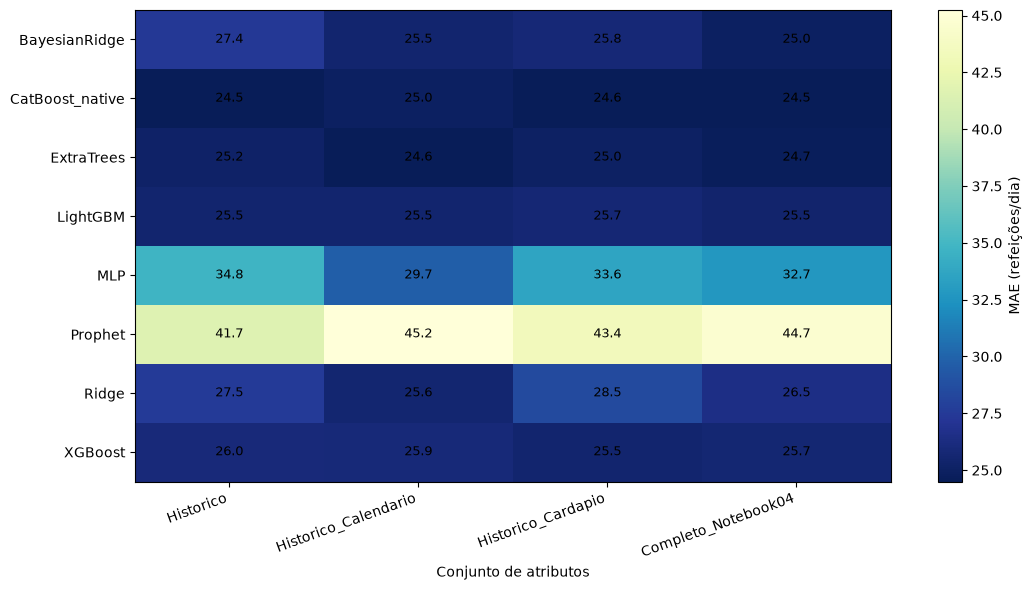

C:\Users\miche\AppData\Local\Temp\ipykernel_23528\1794315746.py:45: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  plot_overall = overall.loc[overall["modelo"].str.contains("::(BayesianRidge|ExtraTrees|LightGBM|CatBoost_native|XGBoost|MLP|Prophet)$", regex=True)].copy()


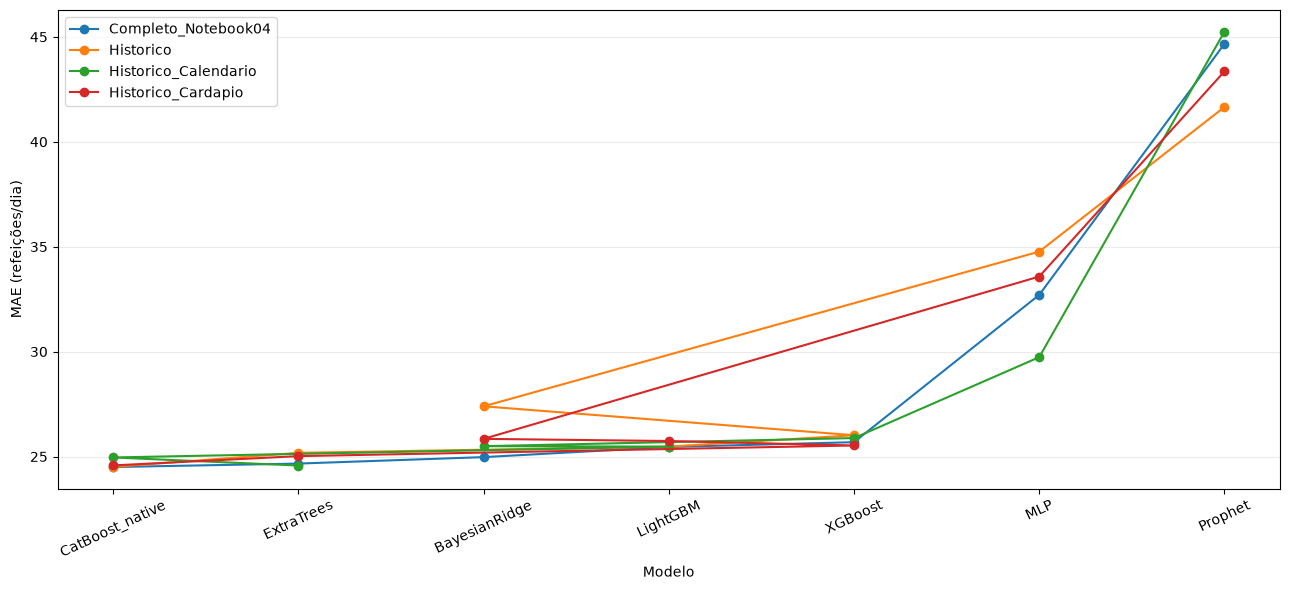

In [5]:
# Efeito de cada grupo: diferenças pareadas do MAE frente ao conjunto completo para os mesmos modelos.
delta_rows = []
for model_name in models:
    key = f"Completo_Notebook04::{model_name}"
    if key not in overall["modelo"].values: continue
    ref_mae = overall.loc[overall["modelo"].eq(key), "MAE"].iloc[0]
    for condition in conditions:
        label = f"{condition}::{model_name}"
        match = overall.loc[overall["modelo"].eq(label)]
        if not match.empty:
            delta_rows.append({"modelo": model_name, "condicao": condition, "MAE": match["MAE"].iloc[0],
                               "MAE_completo": ref_mae, "delta_MAE_vs_completo": match["MAE"].iloc[0]-ref_mae})
deltas = pd.DataFrame(delta_rows)
display(deltas.pivot(index="modelo", columns="condicao", values="delta_MAE_vs_completo").round(2))

# Ganho incremental em MAE frente ao histórico isolado; positivo significa erro menor.
condition_mae = overall.pivot_table(index="modelo_original", columns="condicao", values="MAE")
gain_rows = []
for model_name, row in condition_mae.iterrows():
    if "Historico" not in row or pd.isna(row["Historico"]): continue
    for condition in ["Historico_Calendario", "Historico_Cardapio"]:
        if condition in row and pd.notna(row[condition]):
            gain_rows.append({"modelo": model_name, "condicao": condition,
                              "MAE_historico": row["Historico"], "MAE_com_grupo": row[condition],
                              "ganho_MAE_vs_historico": row["Historico"] - row[condition]})
gains = pd.DataFrame(gain_rows).sort_values(["condicao", "ganho_MAE_vs_historico"], ascending=[True, False])
display(gains.round(3))

# Heatmap de MAE para modelos individuais, não para as linhas de ensemble.
plot_data = overall.loc[overall["modelo_original"].isin(models)].pivot(index="modelo_original", columns="condicao", values="MAE")
plot_data = plot_data.reindex(columns=["Historico", "Historico_Calendario", "Historico_Cardapio", "Completo_Notebook04"])
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(plot_data.to_numpy(), aspect="auto", cmap="YlGnBu_r")
ax.set_xticks(range(len(plot_data.columns)), plot_data.columns, rotation=20, ha="right")
ax.set_yticks(range(len(plot_data.index)), plot_data.index)
for i in range(plot_data.shape[0]):
    for j in range(plot_data.shape[1]):
        value=plot_data.iloc[i,j]
        if pd.notna(value): ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=9)
ax.set_xlabel("Conjunto de atributos")
fig.colorbar(im, ax=ax, label="MAE (refeições/dia)"); fig.tight_layout()
fig.savefig(OUT / "heatmap_mae_modelos_grupos.png", dpi=160, bbox_inches="tight"); plt.show()

# MAE de entradas por configuração e campeão do Notebook 04.
plot_overall = overall.loc[overall["modelo"].str.contains("::(BayesianRidge|ExtraTrees|LightGBM|CatBoost_native|XGBoost|MLP|Prophet)$", regex=True)].copy()
fig, ax = plt.subplots(figsize=(13, 6))
for condition, group in plot_overall.groupby("condicao", sort=False):
    ax.plot(group["modelo_original"], group["MAE"], marker="o", label=condition)
ax.set_ylabel("MAE (refeições/dia)"); ax.set_xlabel("Modelo")
ax.tick_params(axis="x", rotation=25); ax.grid(axis="y", alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "mae_por_condicao_modelo.png", dpi=160, bbox_inches="tight"); plt.show()

In [6]:
# Registra a competição de ablação, as métricas pareadas e as receitas dos ensembles.
comparison.to_csv(OUT / "previsoes_ablation_completo_baselines.csv", index=False, encoding="utf-8-sig")
overall.to_csv(OUT / "metricas_pareadas_gerais.csv", index=False, encoding="utf-8-sig")
annual.to_csv(OUT / "metricas_pareadas_por_ano.csv", index=False, encoding="utf-8-sig")
by_fold.to_csv(OUT / "metricas_pareadas_por_fold.csv", index=False, encoding="utf-8-sig")
deltas.to_csv(OUT / "diferencas_mae_vs_completo.csv", index=False, encoding="utf-8-sig")
gains.to_csv(OUT / "ganhos_mae_por_grupo_vs_historico.csv", index=False, encoding="utf-8-sig")
failures.to_csv(OUT / "falhas_modelos.csv", index=False, encoding="utf-8-sig")
ensemble_audit.to_csv(OUT / "auditoria_ensembles_ablation.csv", index=False, encoding="utf-8-sig")
ensemble_weights.to_csv(OUT / "pesos_ensembles_ablation.csv", index=False, encoding="utf-8-sig")
print(f"Resultados salvos em: {OUT}")

Resultados salvos em: F:\PRODUTO_MESTRADO\resultados\linhas\consumo_cardapio_calendario\05_ablation_grupos_features


## Como interpretar

Uma redução do MAE ao acrescentar calendário sugere sinal preditivo incremental desse grupo dentro desta validação. O mesmo vale para o cardápio. A retirada de um grupo que não piora os resultados pode indicar que ele não acrescenta informação suficiente nesta amostra, mas não prova irrelevância geral. Comparar também WAPE, viés e o balanço entre excesso/falta previstos.

As conclusões são limitadas ao campus, aos anos de 2023–2025, à amostra pareada e aos representantes reavaliados. A popularidade histórica de pratos é calculada sem consumo futuro; categorias ausentes continuam representadas e codificadas no treino. Nenhuma métrica desta ablação afirma desperdício ou falta reais.